# Predicción de Aprobación de Préstamos con Machine Learning

**Fuente original:** https://www.geeksforgeeks.org/machine-learning/loan-approval-prediction-using-machine-learning/

**Modificador y ejecutor:** Carlos Francisco Montoya Urzúa

---
Los préstamos son un requisito fundamental del mundo moderno. Solo con ellos, los bancos reciben una parte importante de sus ganancias totales. Son de gran ayuda para que los estudiantes gestionen sus gastos educativos y de vida, y para que las personas puedan adquirir bienes como casas o automóviles. Sin embargo, cuando se trata de decidir si el perfil de un solicitante es relevante para ser aprobado para un préstamo, los bancos deben considerar muchos aspectos.

Por ello, en este notebook utilizaremos algoritmos de machine learning para facilitar ese trabajo y **predecir si el perfil del candidato es relevante o no**, usando características clave como Estado Civil, Educación, Ingresos del Solicitante, Historial Crediticio, entre otros.

---

## Descripción del Dataset

Puedes descargar el dataset desde este enlace: https://drive.google.com/file/d/1LIvIdqdHDFEGnfzIgEh4L6GFirzsE3US/view?usp=sharing

El dataset contiene **13 características**:

| # | Columna | Descripción |
|---|---------|-------------|
| 1 | Loan_ID | Identificador único del préstamo |
| 2 | Gender | Género del solicitante: Masculino / Femenino |
| 3 | Married | Estado civil del solicitante: Sí / No |
| 4 | Dependents | Indica si el solicitante tiene dependientes o no |
| 5 | Education | Indica si el solicitante es graduado o no |
| 6 | Self_Employed | Define si el solicitante es trabajador independiente: Sí / No |
| 7 | ApplicantIncome | Ingresos del solicitante |
| 8 | CoapplicantIncome | Ingresos del co-solicitante |
| 9 | LoanAmount | Monto del préstamo (en miles) |
| 10 | Loan_Amount_Term | Plazo del préstamo (en meses) |
| 11 | Credit_History | Historial crediticio de pago de deudas del individuo |
| 12 | Property_Area | Área de la propiedad: Rural / Urbana / Semiurbana |
| 13 | Loan_Status | Estado del préstamo: Aprobado (Y) o No aprobado (N) |

------
# Implementación

## Importar Librerías y Dataset

Primero debemos importar las librerías necesarias:

- **Pandas** — Para cargar el DataFrame.
- **Matplotlib** — Para visualizar las características de los datos mediante gráficas de barras.
- **Seaborn** — Para ver la correlación entre características usando un mapa de calor (heatmap).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#data = pd.read_csv("LoanApprovalPrediction.csv")

In [5]:
# ID del archivo público de Google Drive
file_id = '1LIvIdqdHDFEGnfzIgEh4L6GFirzsE3US'

# Construcción de la URL de descarga directa
url = f'https://drive.google.com/uc?export=download&id={file_id}'

# Leer el archivo CSV directamente en un DataFrame de pandas
data = pd.DataFrame()
try:
    data = pd.read_csv(url)
except Exception as e:
    print("Ocurrió un error al cargar el archivo:", e)

Una vez importado el dataset, lo visualizamos con el siguiente comando.

In [6]:
data.head(5)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


**Salida esperada:** Se mostrarán las primeras 5 filas del dataset con columnas como `Loan_ID`, `Gender`, `Married`, `Dependents`, `Education`, `Self_Employed`, `ApplicantIncome`, `CoapplicantIncome`, `LoanAmount`, `Loan_Amount_Term`, `Credit_History`, `Property_Area` y `Loan_Status`.

## Preprocesamiento y Visualización de Datos

Obtenemos el número de columnas con tipo de dato `object` (categóricas).

In [7]:
obj = (data.dtypes == 'object')
print("Variables categóricas:", len(list(obj[obj].index)))

Variables categóricas: 7


**Salida esperada:**
```
Variables categóricas: 7
```

Como `Loan_ID` es completamente único y no está correlacionado con ninguna otra columna, lo eliminamos usando la función `.drop()`.

In [9]:
# Eliminar la columna Loan_ID
#data.drop(['Loan_ID'], axis=1, inplace=True)
columna = 'Loan_ID'

if columna in data.columns:
  data.drop(['Loan_ID'], axis=1, inplace=True)
else:
  print('COLUMNA YA ELIMINADA.')

COLUMNA YA ELIMINADA.


Visualizamos todos los valores únicos de las columnas categóricas mediante gráficas de barras. Esto mostrará qué valor es dominante según nuestro dataset.

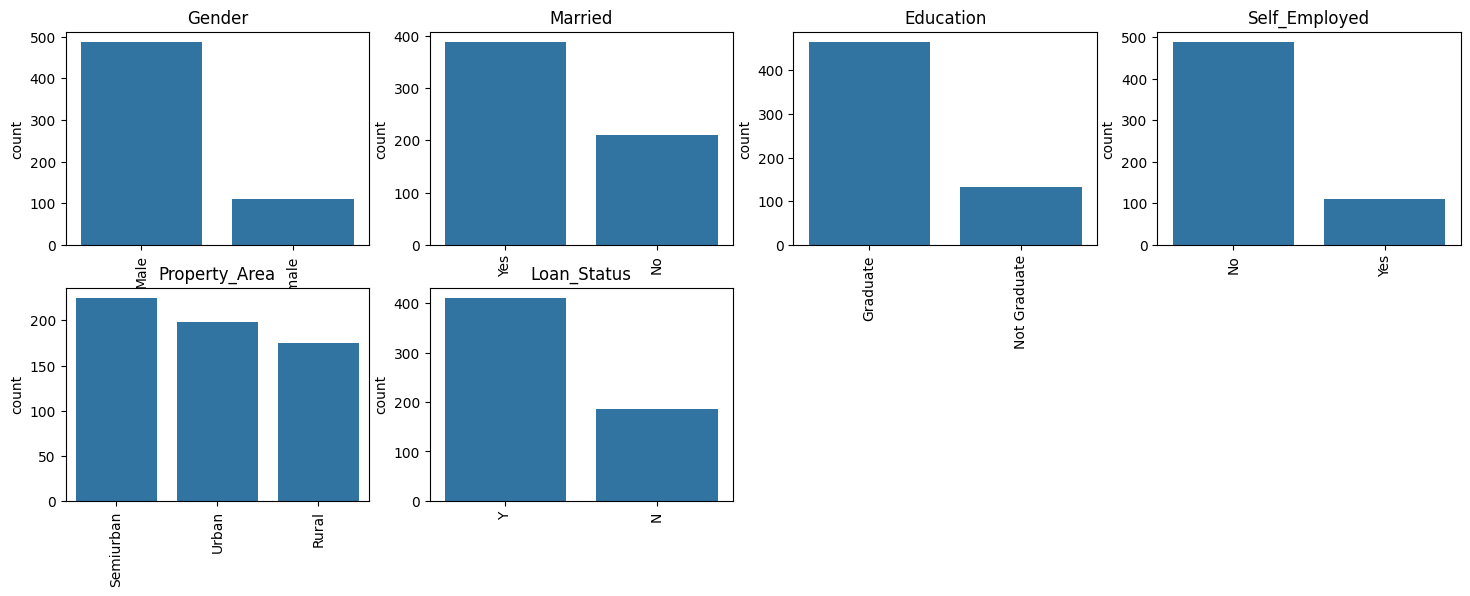

In [11]:
obj = (data.dtypes == 'object')
object_cols = list(obj[obj].index)
plt.figure(figsize=(18, 36))
index = 1

for col in object_cols:
    y = data[col].value_counts()
    plt.subplot(11, 4, index)
    plt.title(str(col))#linea agregada
    plt.xticks(rotation=90)
    sns.barplot(x=list(y.index), y=y)
    index += 1

**Salida esperada:** Gráficas de barras para cada columna categórica mostrando la distribución de sus valores únicos (por ejemplo, `Male`/`Female`, `Yes`/`No`, `Graduate`/`Not Graduate`, etc.).

Como todos los valores categóricos son binarios, podemos usar **Label Encoder** para todas esas columnas y los valores se convertirán al tipo de dato `int`.

In [12]:
# Importar label encoder
from sklearn import preprocessing

# El objeto label_encoder sabe cómo interpretar etiquetas de texto
label_encoder = preprocessing.LabelEncoder()
obj = (data.dtypes == 'object')
for col in list(obj[obj].index):
    data[col] = label_encoder.fit_transform(data[col])

Verificamos nuevamente las columnas con tipo `object` para confirmar que ya no queda ninguna.

In [13]:
# Verificar el número de columnas con datatype == object
obj = (data.dtypes == 'object')
print("Variables categóricas:", len(list(obj[obj].index)))

Variables categóricas: 0


**Salida esperada:**
```
Variables categóricas: 0
```

<Axes: >

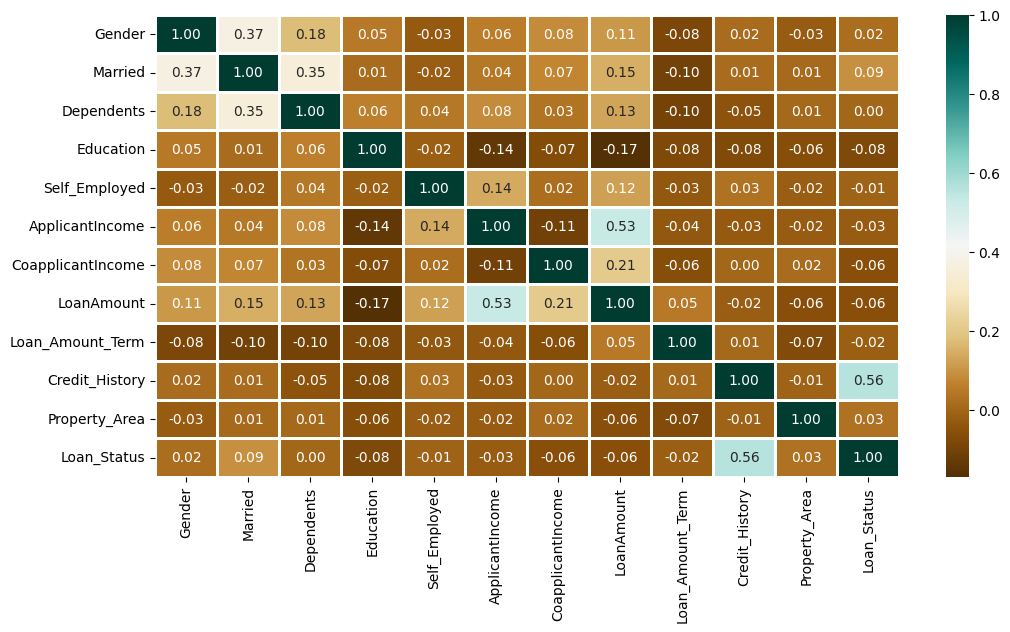

In [14]:
plt.figure(figsize=(12, 6))

sns.heatmap(data.corr(), cmap='BrBG', fmt='.2f',
            linewidths=2, annot=True)

**Salida esperada:** Un mapa de calor que muestra la correlación entre todas las variables del dataset.

El mapa de calor muestra la correlación entre `LoanAmount` e `ApplicantIncome`. También indica que `Credit_History` tiene un alto impacto en `Loan_Status`.

Ahora utilizaremos **Catplot** para visualizar el estado civil y el género del solicitante en relación con el estado del préstamo.

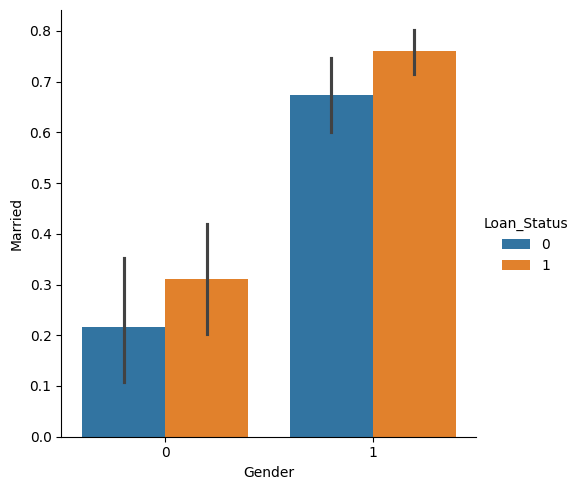

In [15]:
sns.catplot(x="Gender", y="Married",
            hue="Loan_Status",
            kind="bar",
            data=data)

**Salida esperada:** Gráfica de barras categóricas que muestra la relación entre el género (`Gender`), el estado civil (`Married`) y el estado de aprobación del préstamo (`Loan_Status`).

Otra opción para visualizar esta relación. Al final, no me gustó tanto:

In [16]:
import plotly.express as px

#Agrupamos los datos para contar cuántos registros caen en cada combinación
df_grouped = data.groupby(['Gender', 'Married', 'Loan_Status']).size().reset_index(name='Counts')

#Creamos el gráfico interactivo en 3D
fig = px.scatter_3d(
    df_grouped,
    x='Gender',
    y='Married',
    z='Counts',        # El conteo/altura va en el eje Z
    color='Loan_Status',
    size='Counts',     # El tamaño de la burbuja ayuda a ver la magnitud
    title="Análisis de Préstamos en 3D",
    labels={'Counts': 'Cantidad'}
)

#Mostrar el gráfico interactivo
fig.show()

Ahora verificamos si hay valores faltantes en el dataset y los rellenamos con la media de cada columna.

In [17]:
for col in data.columns:
    data[col] = data[col].fillna(data[col].mean())

data.isna().sum()

,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


**Salida esperada:** Todas las columnas deben mostrar `0` valores nulos, lo que indica que no hay datos faltantes. Al no haber valores faltantes, podemos proceder al entrenamiento del modelo.

## División del Dataset

In [18]:
from sklearn.model_selection import train_test_split

X = data.drop(['Loan_Status'], axis=1)
Y = data['Loan_Status']
X.shape, Y.shape

X_train, X_test, Y_train, Y_test = train_test_split(X, Y,
                                                    test_size=0.4,
                                                    random_state=1)
X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((358, 11), (240, 11), (358,), (240,))

**Salida esperada:**
```
((358, 11), (240, 11), (358,), (240,))
```

## Entrenamiento y Evaluación del Modelo

Al tratarse de un problema de clasificación, utilizaremos los siguientes modelos:

- **KNeighborsClassifier** — Clasificador de K-Vecinos más Cercanos
- **RandomForestClassifier** — Clasificador de Bosque Aleatorio
- **Support Vector Classifier (SVC)** — Clasificador de Máquinas de Vectores de Soporte
- **LogisticRegression** — Regresión Logística

Para evaluar la precisión usaremos la función `accuracy_score` de la librería **scikit-learn**.

In [20]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn import metrics

knn = KNeighborsClassifier(n_neighbors=3)
rfc = RandomForestClassifier(n_estimators=7,
                             criterion='entropy',
                             random_state=7)
svc = SVC()
lc = LogisticRegression()

# realizando predicciones sobre el conjunto de entrenamiento
for clf in (rfc, knn, svc, lc):
    clf.fit(X_train, Y_train)
    Y_pred = clf.predict(X_train)#ESTO ES ERRONEO, DEBE USARSE EL CONUNTO DE PRUEBA
    #Y_pred = clf.predict(X_test)
    print("Precisión de ",
          clf.__class__.__name__,
          "=", 100 * metrics.accuracy_score(Y_train, Y_pred))

Precisión de  RandomForestClassifier = 98.04469273743017
Precisión de  KNeighborsClassifier = 78.49162011173185
Precisión de  SVC = 68.71508379888269
Precisión de  LogisticRegression = 80.16759776536313


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning:

lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression



**Salida esperada (conjunto de entrenamiento):**
```
Precisión de  RandomForestClassifier = 98.04469273743017
Precisión de  KNeighborsClassifier   = 78.49162011173185
Precisión de  SVC                    = 68.71508379888269
Precisión de  LogisticRegression     = 80.44692737430168
```

EL CÓDIGO ORIGINAL TENÍA UN ERROR, NO USABA EL CONJUNTO DE PRUEBA.\

Esta versión, además incluye otros modelos para comparar entre sí.

In [49]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import StandardScaler




#Escalador
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


#Inicializar los modelos existentes y los nuevos
knn = KNeighborsClassifier(n_neighbors=3)
rfc = RandomForestClassifier(n_estimators=7, criterion='entropy', random_state=7)
svc = SVC()
lc  = LogisticRegression(max_iter=1000)
# --- NUEVOS MODELOS ---
dtc = DecisionTreeClassifier(max_depth=5, random_state=7)
gnb = GaussianNB()
gbc = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=7)

# Un "Ensemble" que combina las predicciones de los mejores modelos (Votación Mayoritaria)
voting_clf = VotingClassifier(
    estimators=[('lr', lc), ('rf', rfc), ('svc', svc), ('gbc', gbc)],
    voting='hard'
)

#Lista con absolutamente todos los modelos a evaluar
modelos = (rfc, knn, svc, lc, dtc, gnb, gbc, voting_clf)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



In [50]:
#Forzar a Python a tratar las advertencias de convergencia como excepciones (Errores)
warnings.filterwarnings("error", category=ConvergenceWarning)
#IGNORAR ADVERTENCIAS
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*scipy.optimize.*")
warnings.filterwarnings("ignore", message=".*datetime.datetime.utcnow.*")


#ENCABEZADOS DE LA TABLA
print(f"{'Modelo':<35} | {'Precisión Train':<15} | {'Precisión Test':<15}")
print("-" * 73)

#COMPARACIONES
for clf in modelos:
    nombre_modelo = clf.__class__.__name__
    usó_escalado = False

    try:
        # Intento 1: Entrenar con datos normales
        clf.fit(X_train, Y_train)
        Y_pred_train = clf.predict(X_train)
        Y_pred_test = clf.predict(X_test)

    except ConvergenceWarning:
        # Intento 2: Si lanza la advertencia, se captura aquí y usamos datos escalados
        usó_escalado = True
        nombre_modelo += " (Escalado)"

        # Si el modelo es el VotingClassifier, sus modelos internos podrían necesitar datos escalados
        # por lo que entrenamos el modelo directamente con la matriz escalada.
        clf.fit(X_train_scaled, Y_train)
        Y_pred_train = clf.predict(X_train_scaled)
        Y_pred_test = clf.predict(X_test_scaled)

    except Exception as e:
        print(f"Error inesperado en {nombre_modelo}: {e}")
        continue

    # Calcular métricas
    acc_train = 100 * metrics.accuracy_score(Y_train, Y_pred_train)
    acc_test = 100 * metrics.accuracy_score(Y_test, Y_pred_test)

    # Imprimir la fila con el nombre adaptado y sin alertas visuales invasivas
    print(f"{nombre_modelo:<35} | {acc_train:>13.2f}% | {acc_test:>13.2f}%")

print("\n\n")


Modelo                              | Precisión Train | Precisión Test 
-------------------------------------------------------------------------
RandomForestClassifier              |         98.04% |         82.50%
KNeighborsClassifier                |         78.49% |         63.75%
SVC                                 |         68.72% |         69.17%
LogisticRegression (Escalado)       |         80.45% |         82.08%
DecisionTreeClassifier              |         85.20% |         75.00%
GaussianNB                          |         79.05% |         81.67%
GradientBoostingClassifier          |         91.34% |         77.08%
VotingClassifier (Escalado)         |         90.78% |         81.25%





### Predicción sobre el Conjunto de Prueba

Primero, la forma que aparece originalmente en el artículo, el cual ya está desactualizado.

In [51]:
# realizando predicciones sobre el conjunto de prueba
for clf in (rfc, knn, svc, lc):
    clf.fit(X_train, Y_train)
    Y_pred = clf.predict(X_test)
    print("Precisión de ",
          clf.__class__.__name__, "=",
          100 * metrics.accuracy_score(Y_test, Y_pred))

# Restablecer las advertencias a su comportamiento original por seguridad
warnings.resetwarnings()

Precisión de  RandomForestClassifier = 82.5
Precisión de  KNeighborsClassifier = 63.74999999999999
Precisión de  SVC = 69.16666666666667


ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression

**Salida esperada (conjunto de prueba):**
```
Precisión de  RandomForestClassifier = 82.5
Precisión de  KNeighborsClassifier   = 63.74999999999999
Precisión de  SVC                    = 69.16666666666667
Precisión de  LogisticRegression     = 80.83333333333333
```

---


Esta es la versión actualizada, con más modelos a comparar y que permite diferenciar entre si el modelo requiere o no datos escalados.

In [52]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import StandardScaler
from sklearn import metrics


print(f"{'Modelo':<35} | {'Precisión Test':<15}")
print("-" * 53)

# Realizando predicciones sobre el conjunto de prueba
#for clf in (rfc, knn, svc, lc):
for clf in modelos:
    nombre_modelo = clf.__class__.__name__

    try:
        # Intento 1: Entrenar y predecir con datos normales
        clf.fit(X_train, Y_train)
        Y_pred = clf.predict(X_test)

    except ConvergenceWarning:
        # Intento 2: Si no converge, se escala automáticamente
        nombre_modelo += " (Escalado)"
        clf.fit(X_train_scaled, Y_train)
        Y_pred = clf.predict(X_test_scaled)

    except Exception as e:
        print(f"Error inesperado en {nombre_modelo}: {e}")
        continue

    # Calcular la precisión de prueba
    acc_test = 100 * metrics.accuracy_score(Y_test, Y_pred)

    # Imprimir la fila limpia
    print(f"{nombre_modelo:<35} | {acc_test:>13.2f}%")



Modelo                              | Precisión Test 
-----------------------------------------------------
RandomForestClassifier              |         82.50%
KNeighborsClassifier                |         63.75%
SVC                                 |         69.17%
LogisticRegression (Escalado)       |         82.08%
DecisionTreeClassifier              |         75.00%
GaussianNB                          |         81.67%
GradientBoostingClassifier          |         77.08%
VotingClassifier (Escalado)         |         81.25%


##Ejemplo de prediccion de prestamo aprobado para una persona

In [57]:
import pandas as pd


datos_persona = {
    'Gender': [1],                #1 para Male, 0 para Female
    'Married': [1],               #1 para Yes, 0 para No
    'Dependents': [2],
    'Education':         [1],     #1 para Graduate
    'Self_Employed':     [0],
    'ApplicantIncome':   [5000],
    'CoapplicantIncome': [0],
    'LoanAmount': [120],
    'Loan_Amount_Term': [360],
    'Credit_History': [1],        #1 significa que tiene buen historial crediticio
    'Property_Area': [1]
}

# Convertir los datos a un DataFrame de una sola fila
nueva_persona = pd.DataFrame(datos_persona)

modelo_elegido = rfc
nombre_modelo = modelo_elegido.__class__.__name__

#Verificar si el modelo que elegiste usó datos escalados
modelos_que_necesitan_escalado = ['LogisticRegression', 'VotingClassifier']

if nombre_modelo in modelos_que_necesitan_escalado:
    # Si el modelo requirió escalado, transformamos los datos de la persona con el mismo scaler
    persona_procesada = scaler.transform(nueva_persona)
    print(f"-> Usando datos escalados para {nombre_modelo}")
else:
    # Si no, usamos los datos en bruto
    persona_processed = nueva_persona
    print(f"-> Usando datos normales para {nombre_modelo}")

#Realizar la predicción
prediccion = modelo_elegido.predict(persona_processed)

resultado = "APROBADO" if prediccion[0] == 'Y' or prediccion[0] == 1 else "RECHAZADO"

print(f"\nResultado de la predicción con {nombre_modelo}:")
print(f"El préstamo para esta persona ha sido: **{resultado}**")

-> Usando datos normales para RandomForestClassifier

Resultado de la predicción con RandomForestClassifier:
El préstamo para esta persona ha sido: **APROBADO**


Ejecutar hasta el final

In [58]:
#Restablecer las advertencias a su comportamiento original por seguridad
warnings.resetwarnings()

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).




## Conclusión

El **Clasificador de Bosque Aleatorio (Random Forest)** ofrece la mejor precisión con un **82%** sobre el conjunto de prueba. Para obtener mejores resultados, también se pueden utilizar técnicas de aprendizaje por conjuntos como **Bagging** y **Boosting**.

Este proyecto demuestra cómo el machine learning puede automatizar y mejorar el proceso de evaluación de solicitudes de préstamos, tomando en cuenta múltiples características del solicitante para producir predicciones confiables.

---
**Fuente original:** GeeksforGeeks – Loan Approval Prediction using Machine Learning